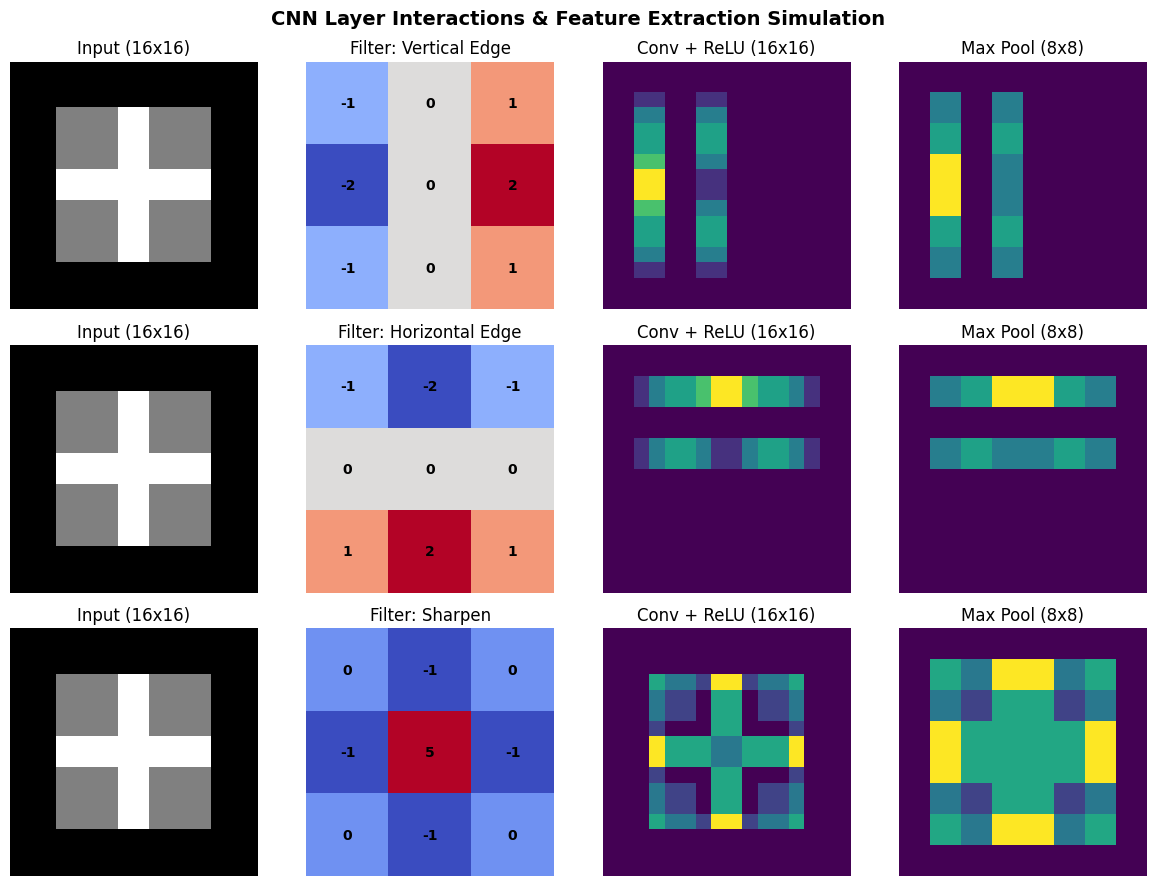

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. INITIALIZE INPUT DATA (Image Data Representation)
# ---------------------------------------------------------
def create_sample_image(size=16):
    """Creates a synthetic grayscale image with a cross/box pattern."""
    image = np.zeros((size, size), dtype=np.float32)
    # Draw a bright square border in the center
    image[3:13, 3:13] = 0.5
    # Draw high-intensity vertical and horizontal lines (a cross)
    image[3:13, 7:9] = 1.0
    image[7:9, 3:13] = 1.0
    return image

# ---------------------------------------------------------
# 2. CONVOLUTIONAL LAYER SIMULATION
# ---------------------------------------------------------
def relu(feature_map):
    """Applies Rectified Linear Unit (ReLU) activation."""
    return np.maximum(0, feature_map)

def convolve2d(image, kernel, stride=1, padding=0):
    """Performs a 2D convolution operation using NumPy."""
    if padding > 0:
        image = np.pad(image, pad_width=padding, mode='constant', constant_values=0)

    img_h, img_w = image.shape
    ker_h, ker_w = kernel.shape

    # Calculate output dimensions
    out_h = (img_h - ker_h) // stride + 1
    out_w = (img_w - ker_w) // stride + 1

    feature_map = np.zeros((out_h, out_w), dtype=np.float32)

    # Slide the kernel across the image
    for y in range(0, out_h):
        for x in range(0, out_w):
            region = image[y*stride : y*stride + ker_h, x*stride : x*stride + ker_w]
            feature_map[y, x] = np.sum(region * kernel)

    return feature_map

# ---------------------------------------------------------
# 3. POOLING LAYER SIMULATION
# ---------------------------------------------------------
def max_pooling2d(feature_map, pool_size=2, stride=2):
    """Performs 2D Max Pooling to downsample the feature map."""
    in_h, in_w = feature_map.shape

    out_h = (in_h - pool_size) // stride + 1
    out_w = (in_w - pool_size) // stride + 1

    pooled_map = np.zeros((out_h, out_w), dtype=np.float32)

    for y in range(0, out_h):
        for x in range(0, out_w):
            region = feature_map[y*stride : y*stride + pool_size, x*stride : x*stride + pool_size]
            pooled_map[y, x] = np.max(region)

    return pooled_map

# ---------------------------------------------------------
# 4. EXECUTION & DISPLAY EXTRACTED FEATURES
# ---------------------------------------------------------
if __name__ == "__main__":
    # Step 1: Initialize Input
    input_image = create_sample_image(size=16)

    # Define 3x3 Convolutional Filters (Kernels)
    filters = {
        "Vertical Edge": np.array([
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]
        ]),
        "Horizontal Edge": np.array([
            [-1, -2, -1],
            [ 0,  0,  0],
            [ 1,  2,  1]
        ]),
        "Sharpen": np.array([
            [ 0, -1,  0],
            [-1,  5, -1],
            [ 0, -1,  0]
        ])
    }

    # Set up Matplotlib grid to visualize the pipeline
    num_filters = len(filters)
    fig, axes = plt.subplots(num_filters, 4, figsize=(12, 3 * num_filters))
    fig.suptitle("CNN Layer Interactions & Feature Extraction Simulation", fontsize=14, fontweight='bold')

    for idx, (name, kernel) in enumerate(filters.items()):
        # Step 2: Apply Convolution + ReLU Activation
        conv_out = convolve2d(input_image, kernel, stride=1, padding=1)
        relu_out = relu(conv_out)

        # Step 3: Apply Max Pooling
        pool_out = max_pooling2d(relu_out, pool_size=2, stride=2)

        # Step 4: Plot each stage of the pipeline
        # Column 0: Original Input
        axes[idx, 0].imshow(input_image, cmap='gray')
        axes[idx, 0].set_title(f"Input ({input_image.shape[0]}x{input_image.shape[1]})")
        axes[idx, 0].axis('off')

        # Column 1: Filter Kernel
        axes[idx, 1].imshow(kernel, cmap='coolwarm')
        axes[idx, 1].set_title(f"Filter: {name}")
        for (j, i), val in np.ndenumerate(kernel):
            axes[idx, 1].text(i, j, f"{val}", ha='center', va='center', color='black', fontweight='bold')
        axes[idx, 1].axis('off')

        # Column 2: Conv + ReLU Feature Map
        axes[idx, 2].imshow(relu_out, cmap='viridis')
        axes[idx, 2].set_title(f"Conv + ReLU ({relu_out.shape[0]}x{relu_out.shape[1]})")
        axes[idx, 2].axis('off')

        # Column 3: Max Pooled Output
        axes[idx, 3].imshow(pool_out, cmap='viridis')
        axes[idx, 3].set_title(f"Max Pool ({pool_out.shape[0]}x{pool_out.shape[1]})")
        axes[idx, 3].axis('off')

    plt.tight_layout()
    plt.show()
